# 02 · Comparativa completa de modelos

Este notebook ejecuta y audita la comparación sobre **todas las filas de construcción**,
con cinco folds exteriores y tres interiores, estratificados y agrupados por predictores
idénticos. El objetivo principal es **Average Precision (AP)**. Un score alto siempre
representa mayor sospecha de fraude.

Hay dos preguntas distintas: cómo funciona cada familia después de elegir sus parámetros
internamente, y cómo funciona el **procedimiento que elige familia, régimen y parámetros**
sin utilizar el fold exterior. El ranking exterior posterior es descriptivo; la entrega
se decide mediante los tres folds interiores de construcción completa (`outer=-1`).

Los datos ya se exploraron antes de fijar este experimento. Por tanto, es una evaluación
interna exploratoria, **no un test externo independiente**. No se utiliza producción para
seleccionar modelos ni hiperparámetros.

In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Markdown, display

RAIZ = Path.cwd().resolve()
assert (RAIZ / "credit_card_construction.csv.zip").is_file(), "Ejecutar desde la raíz del taller."
assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve(), "Seleccionar el kernel de .venv."
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from estudio_datos.comparativa_full import experimento, modelos
SALIDA = experimento.SALIDA
MODULOS = RAIZ / "estudio_datos" / "comparativa_full"

def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))

def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", None)
print("Python:", sys.executable)
print("Resultados:", SALIDA)

Python: /Users/jchulvi/projects/Taller_Deteccion_Anomalias/.venv/bin/python
Resultados: /Users/jchulvi/projects/Taller_Deteccion_Anomalias/estudio_datos/comparativa_full/resultados


## Protocolo, regímenes y uso de las etiquetas

- `todos`: el detector se ajusta con todas las filas de su entrenamiento, sin etiquetas.
- `normales`: se excluyen exclusivamente los fraudes del entrenamiento usando `Class`;
  es un régimen de entrenamiento con normalidad conocida, no completamente no supervisado.
- `supervisado`: el clasificador utiliza ambas etiquetas; también se incluye una referencia
  univariante cuya variable y signo se eligen únicamente dentro de cada entrenamiento.
- `referencia`: score constante para contextualizar AP.

Todos los candidatos utilizan etiquetas **interiores** para seleccionar hiperparámetros.
El escalado se ajusta solo con las filas efectivamente utilizadas por cada modelo y régimen.
Se conserva la población completa; los minibatches del AE, el bootstrap de Random Forest
y el muestreo interno por árbol de Isolation Forest pertenecen a sus algoritmos y se
documentan en los parámetros.

Los duplicados permanecen en el conjunto y viajan juntos entre particiones. No se eliminan
operaciones para acelerar el experimento.

El AE calcula en `float32` y devuelve scores convertidos a `float64`; no se presupone una
aritmética idéntica para todas las familias. Sus 200 épocas máximas son un presupuesto:
si lo alcanza sin parada temprana, no se declara convergencia por ese motivo.

In [2]:
protocolo = experimento.preparar()
integridad = experimento.sellar_datos()
X, y, grupos, archivo_particiones, protocolo = experimento.cargar()
with archivo_particiones:
    particiones = {nombre: archivo_particiones[nombre] for nombre in archivo_particiones.files}
X_produccion = np.load(SALIDA / "X_produccion.npy", mmap_mode="r")

assert X.shape == (170884, 21) and X_produccion.shape == (113923, 21)
assert int(y.sum()) == 295 and np.isfinite(X).all() and np.isfinite(X_produccion).all()
display(pd.Series({
    "filas_construccion": len(X), "columnas": X.shape[1],
    "fraudes": int(y.sum()), "prevalencia": float(y.mean()),
    "grupos_de_predictores": int(np.unique(grupos).size),
    "filas_produccion": len(X_produccion), "protocolo_id": protocolo["id"]
}).to_frame("valor"))
display(pd.DataFrame([
    {"archivo": nombre, "sha256": valor} for nombre, valor in integridad.items()
]))
display(Markdown("**Predictores:** " + ", ".join(protocolo["predictores"])))
print(json.dumps({k: protocolo[k] for k in [
    "semilla", "outer_folds", "inner_folds", "seleccion",
    "preprocesado", "cobertura", "limites"
]}, indent=2, ensure_ascii=False))

,valor
filas_construccion,170884
columnas,21
fraudes,295
prevalencia,0.001726
grupos_de_predictores,166717
filas_produccion,113923
protocolo_id,638141edb70c6551f61114f7f3526db2f8d67d838f706ae3216808a220628201


,archivo,sha256
0,X.npy,797d4be9c7598ba85b766a7871e87e9ed0eab97715af09ec65c88ee028e28df3
1,y.npy,7c793d6c0d9c8a583a4ed44af8c0cb6edf6c325b7f74f0cf2627a9eb64410197
2,grupos.npy,300c85e51790caebd642c08c9dcfd6186c64ac7ba506397d3952773dab9f031c
3,X_produccion.npy,6259fbef314607e7e0e97efc8cd84de186f79c7dea142eabb4fe6cddf9f2294f
4,particiones.npz,bc7c03b2a02c299f6d4ec38a68d5e84213a898fafcef664107326a97529c5456


**Predictores:** X1, X2, X3, X4, X5, X6, X7, X8, X9, X10, X11, X12, X13, X14, X15, X16, X17, X18, X19, X20, Amount

{
  "semilla": 20261020,
  "outer_folds": 5,
  "inner_folds": 3,
  "seleccion": "AP media interior máxima; empate recall@1%, menor tiempo y nombre.",
  "preprocesado": "StandardScaler ajustado con las filas fit de cada régimen; árboles y ECOD sin escalar.",
  "cobertura": "Todas las filas de cada training; normales excluye solo Class=1.",
  "limites": "Validación interna exploratoria de datos previamente examinados; no test externo."
}


In [3]:
# Comprobación visible de los folds: cada fila se evalúa una vez por nivel.
filas_particiones = []
for outer in list(range(5)) + [-1]:
    interiores_eval = []
    if outer >= 0:
        tr, ev = particiones[f"outer_{outer}_train"], particiones[f"outer_{outer}_eval"]
        assert not np.intersect1d(grupos[tr], grupos[ev]).size
        filas_particiones.append({
            "nivel": "exterior", "outer": outer, "inner": -1,
            "train": len(tr), "fraudes_train": int(y[tr].sum()),
            "eval": len(ev), "fraudes_eval": int(y[ev].sum()), "grupos_compartidos": 0
        })
    for inner in range(3):
        tr = particiones[f"outer_{outer}_inner_{inner}_train"]
        ev = particiones[f"outer_{outer}_inner_{inner}_eval"]
        assert not np.intersect1d(grupos[tr], grupos[ev]).size
        interiores_eval.append(ev)
        filas_particiones.append({
            "nivel": "interior", "outer": outer, "inner": inner,
            "train": len(tr), "fraudes_train": int(y[tr].sum()),
            "eval": len(ev), "fraudes_eval": int(y[ev].sum()), "grupos_compartidos": 0
        })
    base = np.arange(len(y)) if outer == -1 else particiones[f"outer_{outer}_train"]
    np.testing.assert_array_equal(np.sort(np.concatenate(interiores_eval)), np.sort(base))
exterior = np.concatenate([particiones[f"outer_{f}_eval"] for f in range(5)])
np.testing.assert_array_equal(np.sort(exterior), np.arange(len(y)))
tabla_particiones = pd.DataFrame(filas_particiones)
display(tabla_particiones)

,nivel,outer,inner,train,fraudes_train,eval,fraudes_eval,grupos_compartidos
0,exterior,0,-1,136707,236,34177,59,0
1,interior,0,0,91138,158,45569,78,0
2,interior,0,1,91138,157,45569,79,0
3,interior,0,2,91138,157,45569,79,0
4,exterior,1,-1,136707,236,34177,59,0
5,interior,1,0,91138,157,45569,79,0
6,interior,1,1,91138,157,45569,79,0
7,interior,1,2,91138,158,45569,78,0
8,exterior,2,-1,136707,236,34177,59,0
9,interior,2,0,91138,157,45569,79,0


## Procedencia y adaptaciones que debemos distinguir

Las demostraciones de MIAX proporcionan las familias y la motivación. La implementación
tabular del estudio está en los módulos enlazados y **no presupone equivalencia numérica**
con las salidas docentes.

| Familia | Fuente y adaptación aplicada |
|---|---|
| GMM | `AD_Probabilidad` y el notebook original del taller; se utiliza **−logdensidad**. |
| PCA | `AD_reconstruccion`; error cuadrático de reconstrucción después de escalar con train. |
| kNN / LOF | `AD_Distancias` y `AD_Tools_Sklearn`; vecinos exactos, protocolo inductivo y geometría compartida entre configuraciones. |
| Isolation Forest | `AD_Tools_Sklearn`; signo invertido del score de sklearn. |
| AE denso | `AD_AE_simple_clase`, celdas 4, 8, 11 y 28; 21 entradas, salida lineal y MSE. Selección interna de épocas por grupos y reajuste completo. |
| RBIG adaptado | `AD_rbig_demo_clase` y [RBIG original fijado a un commit](https://github.com/IPL-UV/rbig/tree/a9124fc07d8e851833802d604fe552b6327ab980): histogramas normalizados, colas exponenciales y logjacobiano estable. Profundidad fija, sin afirmar convergencia. |
| FrozenECOD | Adaptación inductiva del [código oficial de PyOD ECOD](https://pyod.readthedocs.io/en/latest/_modules/pyod/models/ecod.html): ECDF y asimetría congeladas en train, colas inclusivas y suavizado 0.5. Los extremos fuera de soporte saturan. |
| ECOD por cohorte | Implementación oficial de PyOD, que combina train y cohorte consultada. Se consulta cada evaluación completa y se **excluye de la selección principal**. |
| Logística, Random Forest y LightGBM | Comparadores supervisados. Parámetros, tratamiento del desbalance y librerías se documentan en `modelos.py` y en la rejilla fijada. |

Fuente docente local: `../miax/5_Inteligencia_Artificial_Generativa/2026_Anomalias/`.
Las variantes RBIG y FrozenECOD tienen nombre y limitaciones propios; no se presentan como
reproducciones exactas de los paquetes originales.

In [4]:
# Fuentes ejecutables y huellas: todo el código se puede inspeccionar desde el notebook.
fuentes = [
    "modelos.py", "experimento.py", "modelo_ae.py", "modelo_rbig.py",
    "modelo_ecod.py", "modelos_vecinos.py", "analizar.py", "finalizar.py"
]
display(pd.DataFrame([
    {"modulo": nombre, "ruta": str((MODULOS / nombre).relative_to(RAIZ)),
     "sha256": sha256(MODULOS / nombre)}
    for nombre in fuentes
]))
display(Markdown("\n".join(
    f"- [{nombre}]({(MODULOS / nombre).relative_to(RAIZ).as_posix()})"
    for nombre in fuentes
)))
display(Code(inspect.getsource(modelos.Modelo.fit), language="python"))
display(Code(inspect.getsource(modelos.Modelo.score_samples), language="python"))
display(Code(inspect.getsource(experimento.ajustar), language="python"))
display(Code(inspect.getsource(experimento.elegir), language="python"))
display(Code(inspect.getsource(experimento.ejecutar_familia), language="python"))

,modulo,ruta,sha256
0,modelos.py,estudio_datos/comparativa_full/modelos.py,926a3eb0b0dcc3de4aa6b70f2f51a8cf5f413299155bc3c0c0c0ef028ac06951
1,experimento.py,estudio_datos/comparativa_full/experimento.py,4b9e1fc5ac132f692730f8ffccac2b831034061fb9909968fe2b87c2f77028f3
2,modelo_ae.py,estudio_datos/comparativa_full/modelo_ae.py,cfcdc3a8f7094b0b0cf0f2b3cf06b74efe66153e40c23e28f33467309f6c47fe
3,modelo_rbig.py,estudio_datos/comparativa_full/modelo_rbig.py,dde3281be39f86e38cd0c04829ff53b77145d9febe62cf01d1d55ea5c19a8018
4,modelo_ecod.py,estudio_datos/comparativa_full/modelo_ecod.py,757c4b90a294bd505e7449065478d657bc307ee6c2d1d0a44f1f22d80651852c
5,modelos_vecinos.py,estudio_datos/comparativa_full/modelos_vecinos.py,d93f42775a5ce60487a2d744551176c8a9275ce8442c481d38425034b0f96845
6,analizar.py,estudio_datos/comparativa_full/analizar.py,e41b6e0985885de1b09bab2a518bbff2ca3b825224fb65935efbd4fc6e434328
7,finalizar.py,estudio_datos/comparativa_full/finalizar.py,bdcdaa68d9e0383f8791956c89ded61e35b1b6b2210abc0a65255b51582170ba


- [modelos.py](estudio_datos/comparativa_full/modelos.py)
- [experimento.py](estudio_datos/comparativa_full/experimento.py)
- [modelo_ae.py](estudio_datos/comparativa_full/modelo_ae.py)
- [modelo_rbig.py](estudio_datos/comparativa_full/modelo_rbig.py)
- [modelo_ecod.py](estudio_datos/comparativa_full/modelo_ecod.py)
- [modelos_vecinos.py](estudio_datos/comparativa_full/modelos_vecinos.py)
- [analizar.py](estudio_datos/comparativa_full/analizar.py)
- [finalizar.py](estudio_datos/comparativa_full/finalizar.py)

def fit(self, X, y=None):
        p = self.parametros.copy()
        f = self.familia
        self.scaler_ = None if f in SIN_ESCALADO else StandardScaler().fit(X)
        Z = np.asarray(X, dtype=np.float64) if self.scaler_ is None else self.scaler_.transform(X)
        self.training_info_ = {"filas_fit": len(X), "predictores": X.shape[1],
                               "escalado": self.scaler_ is not None}
        with threadpool_limits(limits=self.hilos):
            if f == "constante":
                self.estimador_ = None
            elif f == "univariante":
                resultados = [(average_precision_score(y, signo * Z[:, j]), j, signo)
                              for j in range(Z.shape[1]) for signo in [-1, 1]]
                _, self.variable_, self.signo_ = max(resultados, key=lambda r: (r[0], -r[1], r[2]))
                self.training_info_.update(variable=int(self.variable_), signo=int(self.signo_))
            elif f.startswith("gmm"):
                self.estimador_ = GaussianMixture(random_state=self.semilla, **p).fit(Z)
                self.training_info_.update(convergencia=bool(self.estimador_.converged_),
                                            iteraciones=int(self.estimador_.n_iter_))
                if not self.estimador_.converged_:
                    raise RuntimeError("GMM no convergió: revisar antes de aceptar este ajuste.")
            elif f == "isolation_forest":
                self.estimador_ = IsolationForest(random_state=self.semilla, n_jobs=self.hilos,
                                                  contamination="auto", **p).fit(Z)
                self.training_info_["muestra_por_arbol"] = int(self.estimador_.max_samples_)
            elif f == "pca":
                self.estimador_ = PCA(svd_solver="full", **p).fit(Z)
            elif f in {"lof", "knn"}:
                from .modelos_vecinos import NeighborDetector
                self.estimador_ = NeighborDetector(
                    params={"family": f, **p}, random_state=self.semilla, threads=self.hilos).fit(Z)
            elif f == "autoencoder":
                from .modelo_ae import AutoencoderDetector
                self.estimador_ = AutoencoderDetector(
                    params=p, random_state=self.semilla, threads=self.hilos).fit(Z)
            elif f == "rbig":
                from .modelo_rbig import RBIGDetector
                self.estimador_ = RBIGDetector(
                    params=p, random_state=self.semilla, threads=self.hilos).fit(Z)
            elif f in {"ecod_frozen", "ecod_cohorte"}:
                from .modelo_ecod import ECODDetector, FrozenECODDetector
                cls = FrozenECODDetector if f == "ecod_frozen" else ECODDetector
                self.estimador_ = cls(params=p, random_state=self.semilla, threads=self.hilos).fit(Z)
            elif f == "logistica":
                self.estimador_ = LogisticRegression(
                    max_iter=3000, solver="lbfgs", random_state=self.semilla, **p).fit(Z, y)
                self.training_info_["iteraciones"] = self.estimador_.n_iter_.tolist()
                if np.max(self.estimador_.n_iter_) >= 3000:
                    raise RuntimeError("La regresión logística agotó max_iter.")
            elif f == "random_forest":
                self.estimador_ = RandomForestClassifier(
                    random_state=self.semilla, n_jobs=self.hilos, **p).fit(Z, y)
            elif f == "lightgbm":
                from lightgbm import LGBMClassifier
                self.estimador_ = LGBMClassifier(
                    random_state=self.semilla, n_jobs=self.hilos, verbosity=-1,
                    deterministic=True, force_col_wise=True, **p).fit(Z, y)
            else:
                raise ValueError(f)
        if hasattr(getattr(self, "estimador_", None), "training_info_"):
            self.training_info_["detalle"] = self.estimador_.training_info_
        return self

def score_samples(self, X):
        Z = np.asarray(X, dtype=np.float64) if self.scaler_ is None else self.scaler_.transform(X)
        f = self.familia
        with threadpool_limits(limits=self.hilos):
            if f == "constante":
                s = np.zeros(len(Z))
            elif f == "univariante":
                s = self.signo_ * Z[:, self.variable_]
            elif f.startswith("gmm") or f == "isolation_forest":
                s = -self.estimador_.score_samples(Z)
            elif f == "pca":
                reconstruccion = self.estimador_.inverse_transform(self.estimador_.transform(Z))
                s = np.mean((Z - reconstruccion) ** 2, axis=1)
            elif f in {"logistica", "random_forest", "lightgbm"}:
                s = self.estimador_.predict_proba(Z)[:, 1]
            else:
                s = self.estimador_.score_samples(Z)
        s = np.asarray(s, dtype=np.float64)
        if s.shape != (len(X),) or not np.isfinite(s).all():
            raise ValueError(f"Scores inválidos: {f}")
        return s

def ajustar(familia, regimen, outer, inner, config, tr, ev, X, y, grupos, protocolo, hilos=2):
    fit_idx = tr[y[tr] == 0] if regimen == "normales" else tr
    assert not np.intersect1d(grupos[fit_idx], grupos[ev]).size
    ident = identidad(familia, regimen, outer, inner, config, fit_idx, ev, protocolo)
    base = ruta_ajuste(familia, regimen, outer, inner, config)
    existente = leer_cache(base, ident)
    if existente:
        return existente
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always")
        modelo = Modelo(familia, ident["parametros"], ident["semilla"], hilos)
        modelo.fit(X[fit_idx], y[fit_idx])
        t1 = time.perf_counter()
        scores = modelo.score_samples(X[ev])
        t2 = time.perf_counter()
    return guardar_ajuste(base, ident, scores, y, ev, grupos, len(fit_idx),
                         {"fit_s": t1-t0, "score_s": t2-t1},
                         modelo.training_info_, [str(w.message) for w in capturados])

def elegir(resultados):
    """La mayor AP interior decide; los demás criterios solo resuelven empates."""
    resumen = []
    for c, filas in enumerate(resultados):
        resumen.append({"config": c, "ap_media": float(np.mean([r["metricas"]["ap"] for r in filas])),
                        "ap_sd": float(np.std([r["metricas"]["ap"] for r in filas], ddof=1)),
                        "recall_1pct": float(np.mean([r["metricas"]["recall_0.01"] for r in filas])),
                        "fit_s_media": float(np.mean([r["tiempos"]["fit_s"] for r in filas]))})
    ganador = sorted(resumen, key=lambda r: (-r["ap_media"], -r["recall_1pct"],
                                            r["fit_s_media"], r["config"]))[0]
    return ganador, resumen

def ejecutar_familia(familia, regimen, hilos=2):
    X, y, grupos, splits, protocolo = cargar()
    decisiones = []
    for outer in list(range(5)) + [-1]:
        resultados = []
        for c, _ in enumerate(CONFIGURACIONES[familia]):
            rs = []
            for inner in range(3):
                tr = splits[f"outer_{outer}_inner_{inner}_train"]
                ev = splits[f"outer_{outer}_inner_{inner}_eval"]
                rs.append(ajustar(familia, regimen, outer, inner, c,
                                 tr, ev, X, y, grupos, protocolo, hilos))
            resultados.append(rs)
        ganador, tabla = elegir(resultados)
        decision = {"familia": familia, "regimen": regimen, "outer": outer,
                    "ganador": ganador, "busqueda": tabla, "protocolo": protocolo["id"]}
        if outer != -1:
            meta = ajustar(familia, regimen, outer, -1, ganador["config"],
                           splits[f"outer_{outer}_train"], splits[f"outer_{outer}_eval"],
                           X, y, grupos, protocolo, hilos)
            decision["evaluacion_exterior"] = meta
        decisiones.append(decision)
        escribir_json(SALIDA / "decisiones" / f"{familia}__{regimen}.json", decisiones)
    return decisiones

In [5]:
# La rejilla se muestra antes de ejecutar. No se cambia mirando resultados exteriores.
assert protocolo["configuraciones"] == modelos.CONFIGURACIONES
rejilla = pd.DataFrame([
    {"familia": familia, "regimen": regimen, "config": indice,
     "parametros": json.dumps(parametros, sort_keys=True, ensure_ascii=False),
     "elegible_seleccion_principal": familia != "ecod_cohorte"}
    for familia, opciones in modelos.CONFIGURACIONES.items()
    for regimen in modelos.regimenes(familia)
    for indice, parametros in enumerate(opciones)
])
display(rejilla)
print("Configuraciones por régimen:", len(rejilla))
print("Familias/régimen:", len(rejilla[["familia", "regimen"]].drop_duplicates()))
display(Markdown(
    "Requisitos exactos del entorno: "
    "[requirements.txt](estudio_datos/comparativa_full/requirements.txt)."
))

,familia,regimen,config,parametros,elegible_seleccion_principal
0,constante,referencia,0,{},True
1,univariante,supervisado,0,{},True
2,gmm_fijo,normales,0,"{""covariance_type"": ""full"", ""max_iter"": 1000, ""n_components"": 5, ""n_init"": 1, ""reg_covar"": 1e-06}",True
3,gmm,normales,0,"{""covariance_type"": ""diag"", ""max_iter"": 1000, ""n_components"": 1, ""n_init"": 2, ""reg_covar"": 1e-05}",True
4,gmm,normales,1,"{""covariance_type"": ""full"", ""max_iter"": 1000, ""n_components"": 1, ""n_init"": 2, ""reg_covar"": 1e-05}",True
5,gmm,normales,2,"{""covariance_type"": ""diag"", ""max_iter"": 1000, ""n_components"": 2, ""n_init"": 2, ""reg_covar"": 1e-05}",True
6,gmm,normales,3,"{""covariance_type"": ""full"", ""max_iter"": 1000, ""n_components"": 2, ""n_init"": 2, ""reg_covar"": 1e-05}",True
7,gmm,normales,4,"{""covariance_type"": ""diag"", ""max_iter"": 1000, ""n_components"": 5, ""n_init"": 2, ""reg_covar"": 1e-05}",True
8,gmm,normales,5,"{""covariance_type"": ""full"", ""max_iter"": 1000, ""n_components"": 5, ""n_init"": 2, ""reg_covar"": 1e-05}",True
9,gmm,normales,6,"{""covariance_type"": ""diag"", ""max_iter"": 1000, ""n_components"": 10, ""n_init"": 2, ""reg_covar"": 1e-05}",True


Configuraciones por régimen: 79
Familias/régimen: 24


Requisitos exactos del entorno: [requirements.txt](estudio_datos/comparativa_full/requirements.txt).

## Ejecutar todos los ajustes reales

La siguiente celda ejecuta la rejilla completa. Si ya existen resultados, cada ajuste
se reutiliza únicamente cuando coinciden datos, particiones, parámetros, código y hashes
de scores. Una caché válida acredita un ajuste anterior real: no sustituye experimentos
pendientes por cifras inventadas.

Se utilizan dos hilos por trabajo y hasta cuatro trabajos en el controlador general.
Random Forest se completó repartiendo sus búsquedas entre hasta cinco procesos,
con los mismos datos, parámetros y semillas; la planificación se conserva en
`resultados/logs/ajuste_concurrencia_random_forest.json`. El primer recorrido puede
tardar, especialmente en vecinos exactos. Los logs por familia/régimen están en
`resultados/logs/`; el comando termina con error si queda algún trabajo fallido.

In [6]:
import subprocess

entorno = os.environ.copy()
entorno.pop("PYTHONPATH", None)
entorno["PYTHONDONTWRITEBYTECODE"] = "1"
comando = [
    str(RAIZ / ".venv" / "bin" / "python"),
    "-m", "estudio_datos.comparativa_full.ejecutar",
    "--todos", "--hilos", "2", "--trabajos", "4"
]
print("Ejecutando:", " ".join(comando), flush=True)
subprocess.run(comando, cwd=RAIZ, env=entorno, check=True)

Ejecutando: /Users/jchulvi/projects/Taller_Deteccion_Anomalias/.venv/bin/python -m estudio_datos.comparativa_full.ejecutar --todos --hilos 2 --trabajos 4


INICIO constante/referencia: pid=21674
INICIO univariante/supervisado: pid=21675
INICIO gmm_fijo/normales: pid=21676
INICIO gmm/normales: pid=21677


FIN constante/referencia: exit=0
FIN univariante/supervisado: exit=0
FIN gmm_fijo/normales: exit=0


INICIO gmm/todos: pid=21686
INICIO isolation_forest/normales: pid=21687
INICIO isolation_forest/todos: pid=21688
FIN gmm/normales: exit=0


INICIO pca/normales: pid=21693
FIN isolation_forest/normales: exit=0
FIN isolation_forest/todos: exit=0


...

INICIO ecod_cohorte/todos: pid=21705
INICIO logistica/supervisado: pid=21706
FIN ecod_frozen/todos: exit=0
FIN ecod_cohorte/normales: exit=0


INICIO random_forest/supervisado: pid=21712
INICIO lightgbm/supervisado: pid=21713
FIN ecod_cohorte/todos: exit=0
FIN logistica/supervisado: exit=0


INICIO vecinos/normales: pid=21714
INICIO vecinos/todos: pid=21715
FIN random_forest/supervisado: exit=0
FIN lightgbm/supervisado: exit=0


FIN vecinos/normales: exit=0
FIN vecinos/todos: exit=0


CompletedProcess(args=['/Users/jchulvi/projects/Taller_Deteccion_Anomalias/.venv/bin/python', '-m', 'estudio_datos.comparativa_full.ejecutar', '--todos', '--hilos', '2', '--trabajos', '4'], returncode=0)

In [7]:
# El análisis vuelve a comprobar todas las identidades y recalcula métricas desde scores.
# Se detiene si falta cualquier configuración, fold o régimen previsto.
from estudio_datos.comparativa_full import analizar
seleccion_final = analizar.analizar()
auditoria = leer_json(SALIDA / "auditoria_completitud.json")
assert auditoria["estado"] == "completo"
assert auditoria["ap_pooled_calculada"] is False

por_fold = pd.read_csv(SALIDA / "tabla_por_fold.csv", float_precision="round_trip")
resumen = pd.read_csv(SALIDA / "tabla_resumen_familia_regimen.csv", float_precision="round_trip")
candidatos = pd.read_csv(SALIDA / "tabla_candidatos_interiores.csv", float_precision="round_trip")
procedimiento = pd.read_csv(SALIDA / "tabla_procedimiento_anidado.csv", float_precision="round_trip")
for tabla in (por_fold, resumen, candidatos, procedimiento):
    tabla["candidato"] = tabla["familia"] + " / " + tabla["regimen"]
display(pd.Series({k: v for k, v in auditoria.items()
                   if k not in {"scores_verificados_sha256", "fuentes"}}).to_frame("valor"))

,valor
estado,completo
protocolo,638141edb70c6551f61114f7f3526db2f8d67d838f706ae3216808a220628201
alcance,Búsquedas interiores y evaluaciones exteriores; refit final y producción se verifican por separado.
refit_final_verificado,False
produccion_verificada,False
familias_regimenes,24
ajustes_verificados,1542
evaluaciones_exteriores,120
filas_oof_por_familia_regimen,170884
ap_procedimiento_media,0.841364


In [8]:
# Auditoría de entrenamiento: solo ajustes incluidos en la auditoría completa.
# Lee JSON guardados; no entrena ni cambia parámetros, scores o selección.
registros_gmm, registros_ae = [], []
for fuente in sorted(auditoria["scores_verificados_sha256"]):
    if Path(fuente).parts[1] not in {"gmm", "gmm_fijo", "autoencoder"}:
        continue
    meta_ajuste = leer_json((SALIDA / fuente).with_suffix(".json"))
    identidad_ajuste, entrenamiento = meta_ajuste["identidad"], meta_ajuste["entrenamiento"]
    familia_ajuste, regimen_ajuste = identidad_ajuste["familia"], identidad_ajuste["regimen"]
    if familia_ajuste in {"gmm", "gmm_fijo"}:
        registros_gmm.append({"familia": familia_ajuste, "regimen": regimen_ajuste,
            "convergencia": entrenamiento["convergencia"], "iteraciones": entrenamiento["iteraciones"]})
    else:
        detalle_ae = entrenamiento["detalle"]
        assert detalle_ae["refit_rows"] == meta_ajuste["filas_fit"] == detalle_ae["fit_rows"]
        assert detalle_ae["selected_epochs"] == detalle_ae["refit_epochs"]
        assert detalle_ae["group_overlap"] == 0
        assert detalle_ae["selected_epochs"] <= detalle_ae["selection_epochs_run"] <= detalle_ae["params"]["max_epochs"]
        registros_ae.append({"regimen": regimen_ajuste,
            "selected_epochs": detalle_ae["selected_epochs"], "refit_rows": detalle_ae["refit_rows"],
            "max_epochs": detalle_ae["params"]["max_epochs"],
            "alcanza_limite": detalle_ae["selection_epochs_run"] == detalle_ae["params"]["max_epochs"]})
audit_gmm, audit_ae = pd.DataFrame(registros_gmm), pd.DataFrame(registros_ae)
assert not audit_gmm.empty and not audit_ae.empty
assert audit_gmm["convergencia"].all()
display(Markdown("**Auditoría del entrenamiento.** Ajustes interiores y exteriores completos; incluye la búsqueda final interior, pero no los refits de producción del notebook 03."))
display(audit_gmm.groupby(["familia", "regimen"], as_index=False).agg(
    ajustes=("convergencia", "size"), convergidos=("convergencia", "sum"),
    iteraciones_min=("iteraciones", "min"), iteraciones_max=("iteraciones", "max")))
display(audit_ae.groupby("regimen", as_index=False).agg(
    ajustes=("selected_epochs", "size"), selected_epochs_min=("selected_epochs", "min"),
    selected_epochs_max=("selected_epochs", "max"), refit_rows_min=("refit_rows", "min"),
    refit_rows_max=("refit_rows", "max"), max_epochs=("max_epochs", "max"),
    busquedas_que_alcanzan_limite=("alcanza_limite", "sum")))
presupuestos_ae = ", ".join(str(v) for v in sorted(audit_ae["max_epochs"].unique()))
display(Markdown(
    f"**Límite del AE:** el presupuesto máximo es de **{presupuestos_ae} épocas**; "
    f"**{int(audit_ae['alcanza_limite'].sum())} de {len(audit_ae)}** búsquedas internas alcanzan ese límite. "
    f"Las épocas seleccionadas van de **{int(audit_ae['selected_epochs'].min())} a "
    f"{int(audit_ae['selected_epochs'].max())}**. Se ha comprobado el reajuste completo "
    "de cada partición y la separación de sus grupos internos. El presupuesto es finito: "
    "alcanzarlo no acredita convergencia ni optimalidad global. La convergencia declarada "
    "por GMM corresponde a su criterio de parada, tampoco demuestra un óptimo global."
))

**Auditoría del entrenamiento.** Ajustes interiores y exteriores completos; incluye la búsqueda final interior, pero no los refits de producción del notebook 03.

,familia,regimen,ajustes,convergidos,iteraciones_min,iteraciones_max
0,gmm,normales,149,149,2,99
1,gmm,todos,149,149,2,80
2,gmm_fijo,normales,23,23,13,57


,regimen,ajustes,selected_epochs_min,selected_epochs_max,refit_rows_min,refit_rows_max,max_epochs,busquedas_que_alcanzan_limite
0,normales,41,187,200,90980,136472,200,40
1,todos,41,97,200,91138,136708,200,35


**Límite del AE:** el presupuesto máximo es de **200 épocas**; **75 de 82** búsquedas internas alcanzan ese límite. Las épocas seleccionadas van de **97 a 200**. Se ha comprobado el reajuste completo de cada partición y la separación de sus grupos internos. El presupuesto es finito: alcanzarlo no acredita convergencia ni optimalidad global. La convergencia declarada por GMM corresponde a su criterio de parada, tampoco demuestra un óptimo global.

## Resultados por familia y fold

AP se calcula **dentro de cada fold exterior** y se resume mediante media, desviación
estándar y rango. No concatenamos scores crudos de modelos distintos para calcular una
AP conjunta. La desviación entre cinco folds es descriptiva, no un intervalo de confianza.

,familia,regimen,folds,filas_oof,fraudes_oof,elegible,ap_media,ap_sd,ap_min,ap_max,delta_ap_gmm_media,folds_mejor_gmm,fit_s_media,score_s_media,precision_0.002_media,recall_0.002_media,precision_0.01_media,recall_0.01_media,precision_0.02_media,recall_0.02_media,candidato
0,lightgbm,supervisado,5,170884,295,True,0.841364,4.475545e-02,0.767046,0.870231,0.193329,5,4.324399,0.552969,0.724638,0.847458,0.152632,0.884746,0.077778,0.901695,lightgbm / supervisado
1,random_forest,supervisado,5,170884,295,True,0.834397,2.982430e-02,0.793136,0.867290,0.186361,5,41.052374,0.219251,0.724638,0.847458,0.152047,0.881356,0.077778,0.901695,random_forest / supervisado
2,logistica,supervisado,5,170884,295,True,0.760769,4.824820e-02,0.695524,0.828470,0.112734,5,0.082766,0.004442,0.707246,0.827119,0.150877,0.874576,0.078070,0.905085,logistica / supervisado
3,autoencoder,normales,5,170884,295,True,0.657655,1.314014e-01,0.428339,0.745113,0.009619,3,22.570439,0.008864,0.620290,0.725424,0.142690,0.827119,0.072807,0.844068,autoencoder / normales
4,gmm_fijo,normales,5,170884,295,True,0.648035,8.521333e-02,0.534498,0.749582,0.000000,0,2.045995,0.020344,0.591304,0.691525,0.143275,0.830508,0.072807,0.844068,gmm_fijo / normales
5,gmm,normales,5,170884,295,True,0.637745,8.271087e-02,0.562868,0.770206,-0.010291,4,6.260272,0.014676,0.579710,0.677966,0.142690,0.827119,0.073392,0.850847,gmm / normales
6,univariante,supervisado,5,170884,295,True,0.620613,5.144892e-02,0.563986,0.688093,-0.027422,2,0.487754,0.003711,0.611594,0.715254,0.135673,0.786441,0.068713,0.796610,univariante / supervisado
7,isolation_forest,normales,5,170884,295,True,0.469944,3.968121e-02,0.428055,0.524454,-0.178091,0,5.115140,0.572465,0.466667,0.545763,0.142105,0.823729,0.073099,0.847458,isolation_forest / normales
8,knn,normales,5,170884,295,True,0.457488,6.135618e-02,0.392210,0.521454,-0.190547,0,27.118258,0.001641,0.501449,0.586441,0.145029,0.840678,0.073099,0.847458,knn / normales
9,pca,normales,5,170884,295,True,0.454893,7.842055e-02,0.363826,0.535858,-0.193143,0,0.069707,0.008783,0.423188,0.494915,0.140936,0.816949,0.071053,0.823729,pca / normales


,familia,regimen,outer,config,ap,roc_auc,filas,fraudes,filas_fit,precision_0.01,recall_0.01,fit_s,score_s
0,constante,referencia,0,0,0.001726,0.500000,34177,59,136707,0.000000,0.000000,0.005944,0.002595
1,constante,referencia,1,0,0.001726,0.500000,34177,59,136707,0.000000,0.000000,0.004680,0.002880
2,constante,referencia,2,0,0.001726,0.500000,34177,59,136707,0.002924,0.016949,0.003467,0.002312
3,constante,referencia,3,0,0.001726,0.500000,34177,59,136707,0.000000,0.000000,0.003406,0.002278
4,constante,referencia,4,0,0.001726,0.500000,34176,59,136708,0.002924,0.016949,0.003936,0.002518
5,univariante,supervisado,0,0,0.649180,0.804832,34177,59,136707,0.128655,0.745763,0.510877,0.002856
6,univariante,supervisado,1,0,0.625753,0.826542,34177,59,136707,0.131579,0.762712,0.471803,0.003277
7,univariante,supervisado,2,0,0.563986,0.964873,34177,59,136707,0.143275,0.830508,0.470173,0.003719
8,univariante,supervisado,3,0,0.688093,0.877981,34177,59,136707,0.146199,0.847458,0.491753,0.003538
9,univariante,supervisado,4,0,0.576056,0.808881,34176,59,136708,0.128655,0.745763,0.494166,0.005167


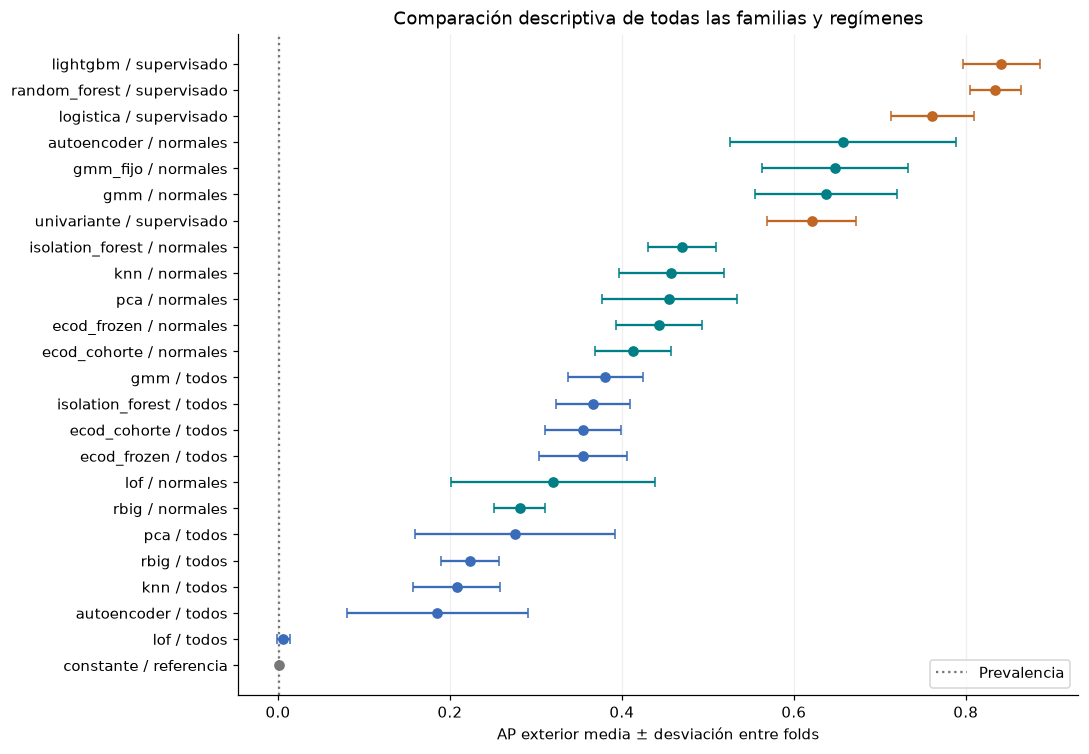

In [9]:
display(resumen)
display(por_fold[[
    "familia", "regimen", "outer", "config", "ap", "roc_auc", "filas", "fraudes",
    "filas_fit", "precision_0.01", "recall_0.01", "fit_s", "score_s"
]])

# Gráfico 1: AP media y dispersión por candidato.
orden = resumen.sort_values(["ap_media", "candidato"]).reset_index(drop=True)
colores = {"normales": "#007f86", "todos": "#3b6cba",
           "supervisado": "#c06724", "referencia": "#777777"}
fig, ax = plt.subplots(figsize=(10, max(6, len(orden) * 0.29)))
for i, fila in orden.iterrows():
    ax.errorbar(fila["ap_media"], i, xerr=fila["ap_sd"], fmt="o",
                color=colores[fila["regimen"]], capsize=3)
ax.set_yticks(range(len(orden)), orden["candidato"])
ax.axvline(float(y.mean()), ls=":", color="#777777", label="Prevalencia")
ax.set(xlabel="AP exterior media ± desviación entre folds",
       title="Comparación descriptiva de todas las familias y regímenes")
ax.grid(axis="x", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

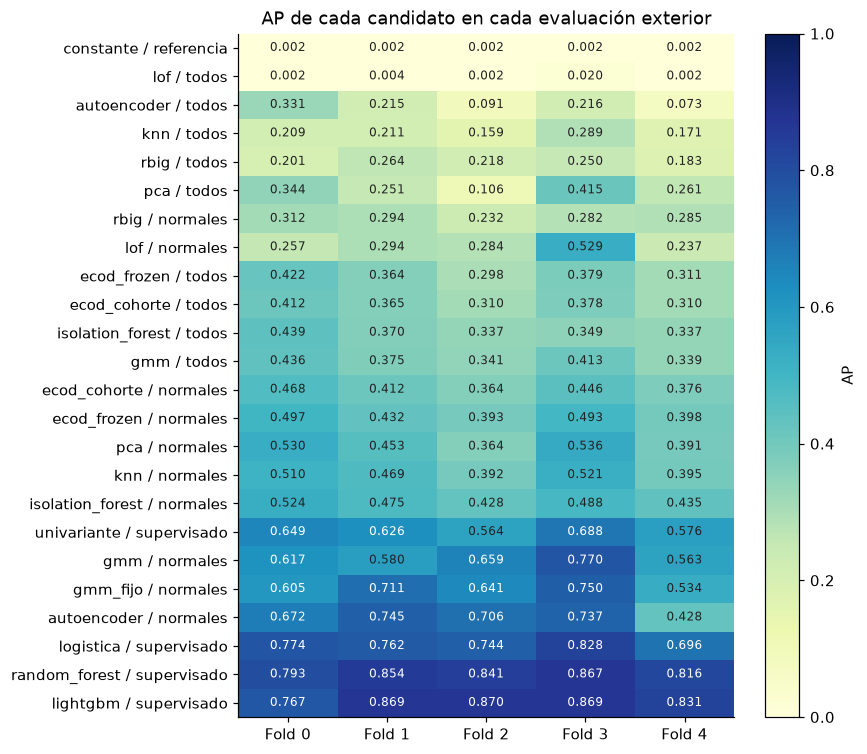

In [10]:
# Gráfico 2: matriz de AP por fold, sin mezclar escalas de scores.
matriz_ap = por_fold.pivot(index="candidato", columns="outer", values="ap").reindex(orden["candidato"])
fig, ax = plt.subplots(figsize=(8, max(6, len(matriz_ap) * 0.29)))
imagen = ax.imshow(matriz_ap.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
ax.set_yticks(range(len(matriz_ap)), matriz_ap.index)
ax.set_xticks(range(5), [f"Fold {i}" for i in range(5)])
for i in range(len(matriz_ap)):
    for j in range(5):
        valor = matriz_ap.iloc[i, j]
        ax.text(j, i, f"{valor:.3f}", ha="center", va="center",
                color="white" if valor > 0.60 else "#222222", fontsize=8)
ax.set_title("AP de cada candidato en cada evaluación exterior")
fig.colorbar(imagen, ax=ax, label="AP")
plt.tight_layout()
plt.show()

## Evaluación del procedimiento de selección

En cada fold exterior se escoge familia, régimen y configuración solo con los tres folds
interiores de su entrenamiento. La tabla siguiente muestra qué escogió ese procedimiento
y cómo rindió después en operaciones exteriores. Es distinta del ranking retrospectivo
de la media de cada familia.

Las curvas precisión–recall se dibujan separadamente por fold: cada curva procede de
un único modelo y su propia evaluación.

In [11]:
display(procedimiento[[
    "outer", "familia", "regimen", "config", "ap_interior_seleccion",
    "ap", "ap_baseline_gmm", "delta_ap_gmm", "recall_0.01", "precision_0.01"
]])
display(pd.Series({
    "AP_media_procedimiento": procedimiento["ap"].mean(),
    "AP_sd_procedimiento": procedimiento["ap"].std(ddof=1),
    "delta_AP_pareada_media_vs_GMM_fijo": procedimiento["delta_ap_gmm"].mean(),
    "folds_evaluados": len(procedimiento)
}).to_frame("valor"))

,outer,familia,regimen,config,ap_interior_seleccion,ap,ap_baseline_gmm,delta_ap_gmm,recall_0.01,precision_0.01
0,0,lightgbm,supervisado,1,0.855540,0.767046,0.604590,0.162456,0.813559,0.140351
1,1,lightgbm,supervisado,5,0.837165,0.869091,0.710528,0.158562,0.881356,0.152047
2,2,lightgbm,supervisado,5,0.852176,0.870231,0.640979,0.229252,0.915254,0.157895
3,3,lightgbm,supervisado,5,0.833508,0.869329,0.749582,0.119747,0.949153,0.163743
4,4,lightgbm,supervisado,3,0.841880,0.831125,0.534498,0.296627,0.864407,0.149123


,valor
AP_media_procedimiento,0.841364
AP_sd_procedimiento,0.044755
delta_AP_pareada_media_vs_GMM_fijo,0.193329
folds_evaluados,5.000000


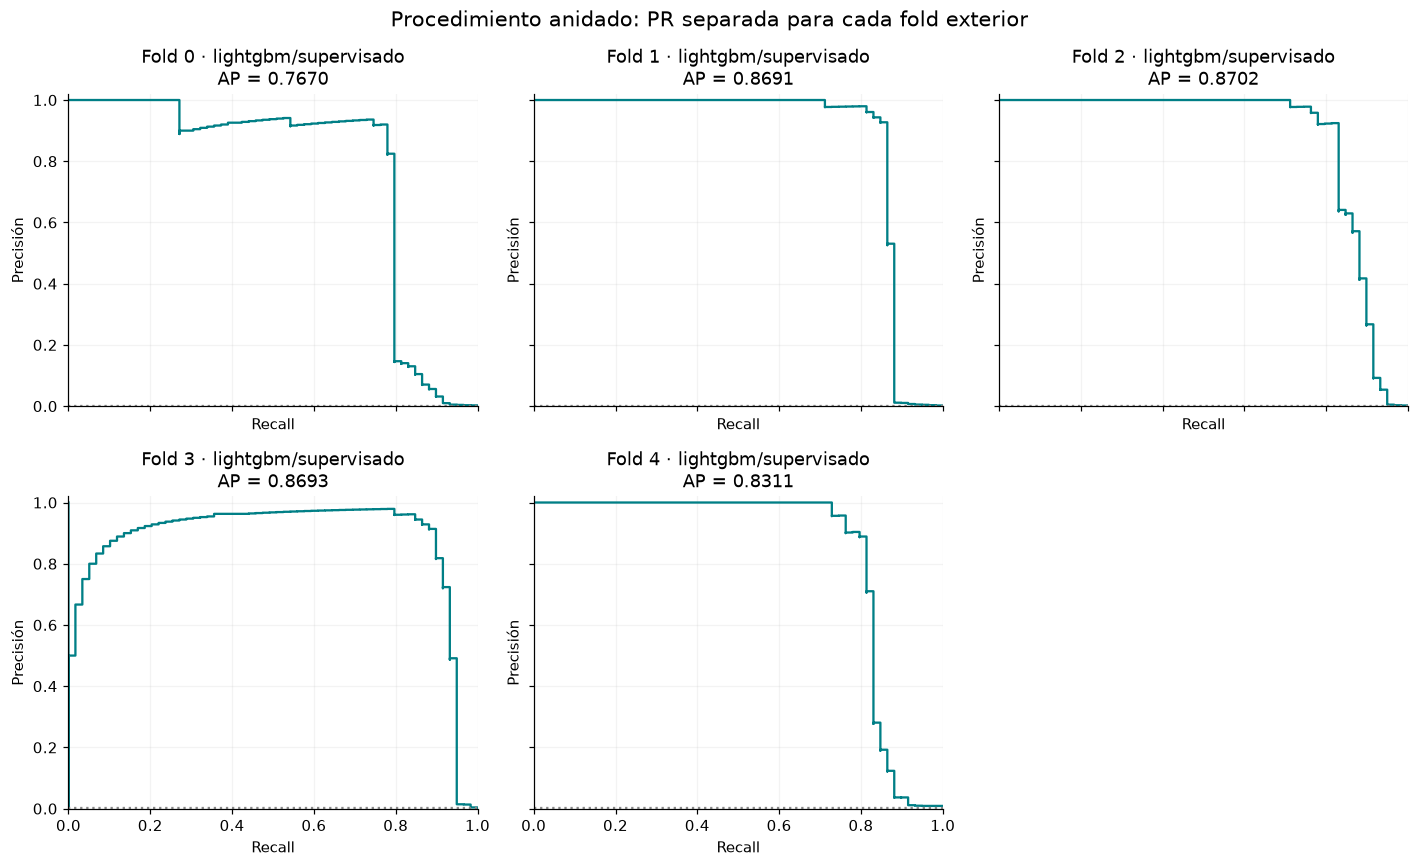

In [12]:
# Gráfico 3: cinco curvas PR independientes del selector anidado.
from sklearn.metrics import average_precision_score, precision_recall_curve

scores_selector = pd.read_csv(
    SALIDA / "scores_oof" / "procedimiento_anidado.csv", float_precision="round_trip"
)
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for fold, ax in zip(range(5), axes.flat):
    datos_fold = scores_selector.loc[scores_selector["outer"].eq(fold)]
    precision, recall, _ = precision_recall_curve(datos_fold["y"], datos_fold["score"])
    ap = average_precision_score(datos_fold["y"], datos_fold["score"])
    registro = procedimiento.loc[procedimiento["outer"].eq(fold)].iloc[0]
    assert np.isclose(ap, registro["ap"], rtol=1e-10, atol=1e-12)
    ax.step(recall, precision, where="post", color="#007f86")
    ax.axhline(datos_fold["y"].mean(), ls=":", color="#888888")
    ax.set(title=f"Fold {fold} · {registro['familia']}/{registro['regimen']}\nAP = {ap:.4f}",
           xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.15)
axes.flat[-1].axis("off")
fig.suptitle("Procedimiento anidado: PR separada para cada fold exterior", fontsize=14)
plt.tight_layout()
plt.show()

## Presupuesto de revisión, comparación pareada y tiempos

Los presupuestos del 0,2 %, 1 % y 2 % representan cuántas operaciones de cada fold
se revisarían al priorizar los scores más altos. Se muestran precisión y recall.
Los empates en el corte se resuelven por el índice original y se registran:
esa regla puede influir en referencias constantes o scores discretizados.

Los tiempos siguientes son medias de los ajustes exteriores y de su puntuación.
Se midieron en un Mac compartido, con hasta cuatro trabajos simultáneos
(cinco en la finalización de Random Forest) y dos hilos por trabajo; los cinco folds utilizan entrenamientos diferentes. No son una medición
controlada de latencia de producción.
**LOF y kNN comparten el cálculo de vecinos**: en estos ajustes de validación,
`fit_s` incluye el escalado y la búsqueda de vecinos tanto de **entrenamiento como de
consulta**. `score_s` mide solo la agregación del score a partir de los vecinos ya
calculados; no representa por sí solo el coste de puntuar nuevas operaciones.
La geometría aparece en ambos candidatos y no se debe sumar como si fueran trabajos
independientes. La tabla de desglose utiliza únicamente los diez ajustes exteriores
de LOF (dos regímenes × cinco folds), sin repetir el coste en kNN. Estas medias
tampoco son el tiempo total de toda la búsqueda de hiperparámetros.

,familia,regimen,precision_0.002_media,recall_0.002_media,precision_0.01_media,recall_0.01_media,precision_0.02_media,recall_0.02_media
0,lightgbm,supervisado,0.724638,0.847458,0.152632,0.884746,0.077778,0.901695
1,random_forest,supervisado,0.724638,0.847458,0.152047,0.881356,0.077778,0.901695
2,logistica,supervisado,0.707246,0.827119,0.150877,0.874576,0.078070,0.905085
3,autoencoder,normales,0.620290,0.725424,0.142690,0.827119,0.072807,0.844068
4,gmm_fijo,normales,0.591304,0.691525,0.143275,0.830508,0.072807,0.844068
5,gmm,normales,0.579710,0.677966,0.142690,0.827119,0.073392,0.850847
6,univariante,supervisado,0.611594,0.715254,0.135673,0.786441,0.068713,0.796610
7,isolation_forest,normales,0.466667,0.545763,0.142105,0.823729,0.073099,0.847458
8,knn,normales,0.501449,0.586441,0.145029,0.840678,0.073099,0.847458
9,pca,normales,0.423188,0.494915,0.140936,0.816949,0.071053,0.823729


,familia,regimen,outer,empatados_0.002,empatados_0.01,empatados_0.02
0,constante,referencia,0,34177,34177,34177
1,constante,referencia,1,34177,34177,34177
2,constante,referencia,2,34177,34177,34177
3,constante,referencia,3,34177,34177,34177
4,constante,referencia,4,34176,34176,34176
5,univariante,supervisado,0,1,12,26
6,univariante,supervisado,1,1,22,20
7,univariante,supervisado,2,1,3,8
8,univariante,supervisado,3,1,17,29
9,univariante,supervisado,4,1,18,36


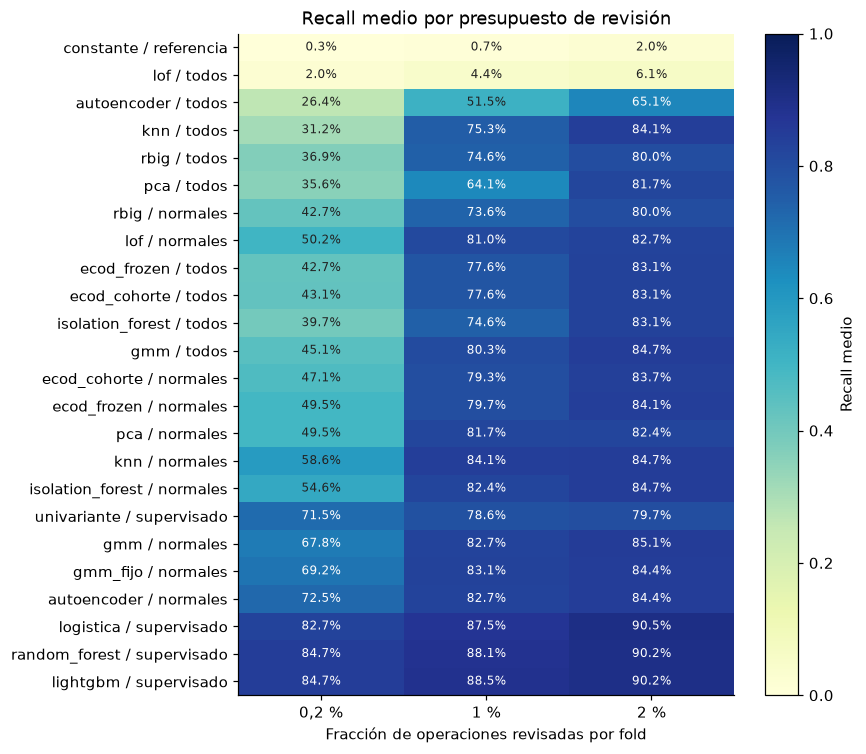

In [13]:
presupuestos = ["0.002", "0.01", "0.02"]
columnas_presupuesto = [
    f"{metrica}_{q}_media" for q in presupuestos for metrica in ("precision", "recall")
]
display(resumen[["familia", "regimen"] + columnas_presupuesto])
display(por_fold[["familia", "regimen", "outer"] +
                 [f"empatados_{q}" for q in presupuestos]])

# Gráfico 4: recall medio a distintos presupuestos para todos los candidatos.
matriz_recall = orden.set_index("candidato")[[f"recall_{q}_media" for q in presupuestos]]
fig, ax = plt.subplots(figsize=(8, max(6, len(matriz_recall) * 0.29)))
imagen = ax.imshow(matriz_recall.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
ax.set_yticks(range(len(matriz_recall)), matriz_recall.index)
ax.set_xticks(range(3), ["0,2 %", "1 %", "2 %"])
for i in range(len(matriz_recall)):
    for j in range(3):
        valor = matriz_recall.iloc[i, j]
        ax.text(j, i, f"{valor:.1%}", ha="center", va="center",
                color="white" if valor > 0.60 else "#222222", fontsize=8)
ax.set(xlabel="Fracción de operaciones revisadas por fold",
       title="Recall medio por presupuesto de revisión")
fig.colorbar(imagen, ax=ax, label="Recall medio")
plt.tight_layout()
plt.show()

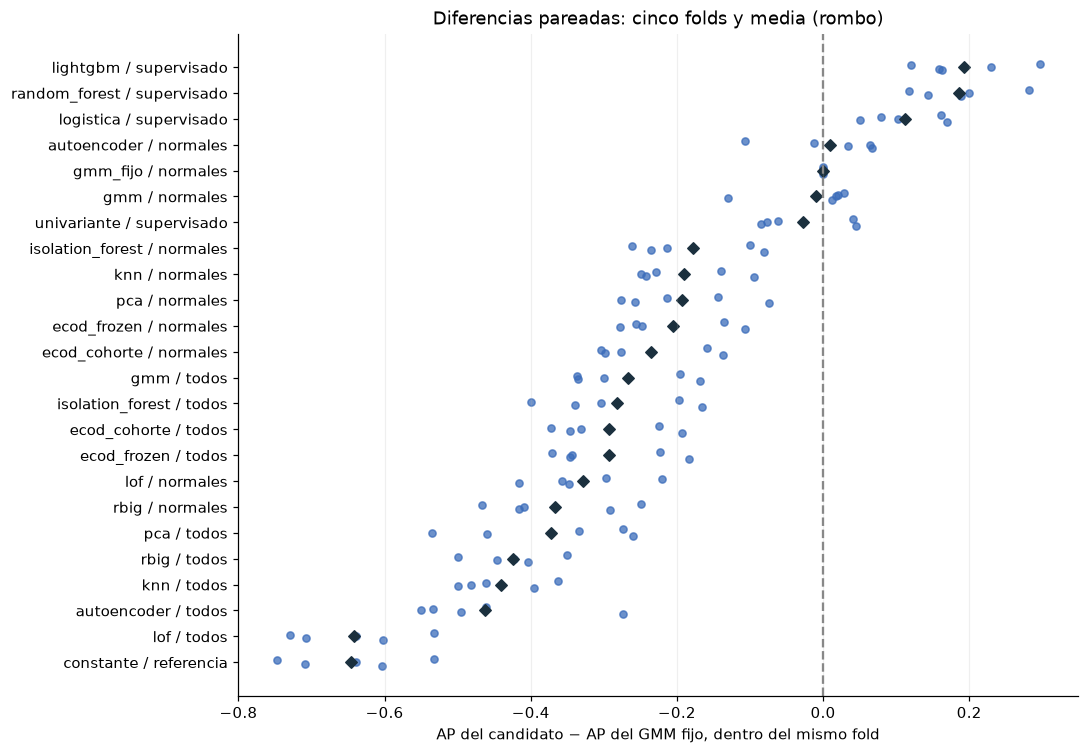

In [14]:
# Gráfico 5: diferencia pareada respecto al GMM fijo del taller.
fig, ax = plt.subplots(figsize=(10, max(6, len(orden) * 0.29)))
for i, candidato in enumerate(orden["candidato"]):
    valores = por_fold.loc[por_fold["candidato"].eq(candidato)].sort_values("outer")
    ax.scatter(valores["delta_ap_gmm"], i + np.linspace(-0.13, 0.13, 5),
               color="#3b6cba", s=22, alpha=0.75)
    ax.scatter(valores["delta_ap_gmm"].mean(), i, marker="D", color="#1b303e", s=28)
ax.axvline(0, color="#888888", ls="--")
ax.set_yticks(range(len(orden)), orden["candidato"])
ax.set(xlabel="AP del candidato − AP del GMM fijo, dentro del mismo fold",
       title="Diferencias pareadas: cinco folds y media (rombo)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

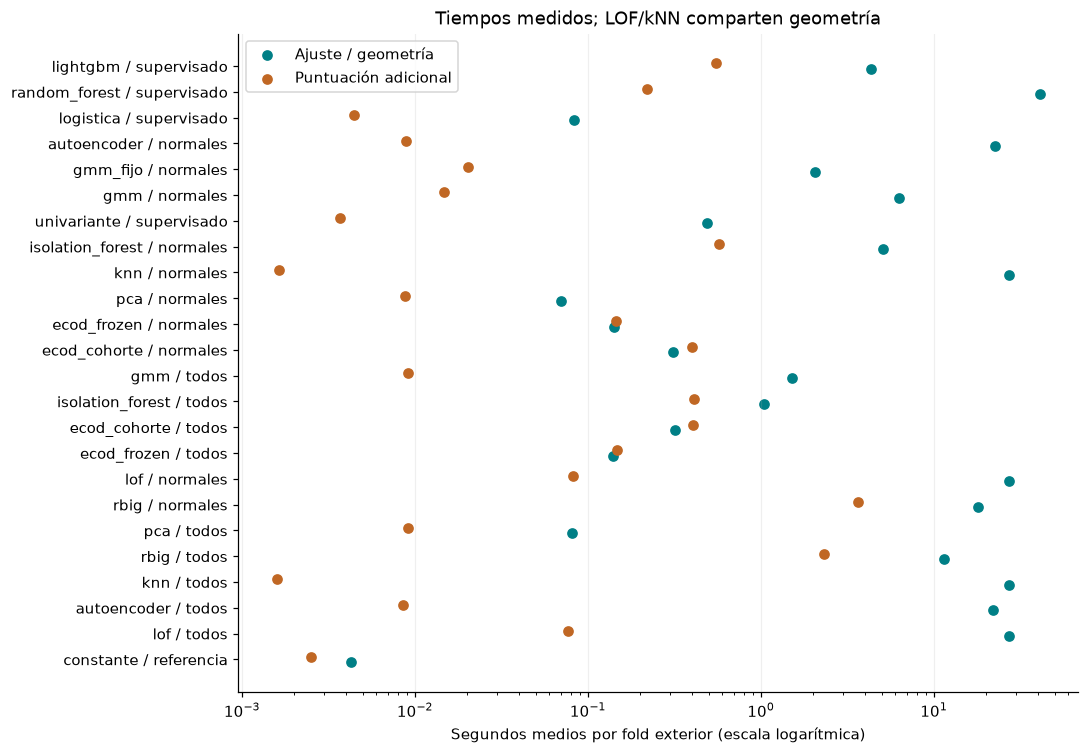

,familia,regimen,fit_s_media,score_s_media
0,lightgbm,supervisado,4.324399,0.552969
1,random_forest,supervisado,41.052374,0.219251
2,logistica,supervisado,0.082766,0.004442
3,autoencoder,normales,22.570439,0.008864
4,gmm_fijo,normales,2.045995,0.020344
5,gmm,normales,6.260272,0.014676
6,univariante,supervisado,0.487754,0.003711
7,isolation_forest,normales,5.115140,0.572465
8,knn,normales,27.118258,0.001641
9,pca,normales,0.069707,0.008783


In [15]:
# Gráfico 6: coste exterior por candidato, sin sumar geometrías compartidas.
fig, ax = plt.subplots(figsize=(10, max(6, len(orden) * 0.29)))
posiciones = np.arange(len(orden))
ax.scatter(orden["fit_s_media"], posiciones - 0.10, label="Ajuste / geometría", color="#007f86")
ax.scatter(orden["score_s_media"], posiciones + 0.10, label="Puntuación adicional", color="#c06724")
ax.set_xscale("log")
ax.set_yticks(posiciones, orden["candidato"])
ax.set(xlabel="Segundos medios por fold exterior (escala logarítmica)",
       title="Tiempos medidos; LOF/kNN comparten geometría")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()
display(resumen[["familia", "regimen", "fit_s_media", "score_s_media"]])

In [16]:
# Desglose de la geometría compartida: solo LOF, una fila por régimen y fold.
# Se leen metadatos auditados; no se vuelven a calcular vecinos ni scores.
ajustes_lof = por_fold.loc[por_fold["familia"].eq("lof")].sort_values(["regimen", "outer"])
pares_esperados = {(regimen, fold) for regimen in ("normales", "todos") for fold in range(5)}
assert len(ajustes_lof) == 10
assert set(zip(ajustes_lof["regimen"], ajustes_lof["outer"])) == pares_esperados
filas_desglose_vecinos = []
for registro in ajustes_lof.to_dict("records"):
    ruta_meta = (SALIDA / registro["fuente_ajuste"]).with_suffix(".json")
    meta_vecinos = leer_json(ruta_meta)
    identidad_vecinos = meta_vecinos["identidad"]
    assert identidad_vecinos["familia"] == "lof" and identidad_vecinos["inner"] == -1
    assert identidad_vecinos["regimen"] == registro["regimen"]
    assert identidad_vecinos["outer"] == registro["outer"]
    assert identidad_vecinos["config"] == registro["config"]
    assert meta_vecinos["entrenamiento"]["geometria_compartida"] is True
    detalle_vecinos = meta_vecinos["entrenamiento"]["detalle"]
    assert detalle_vecinos["n_train"] == registro["filas_fit"]
    assert detalle_vecinos["n_query"] == registro["filas"]
    for tipo_tiempo in ("fit_s", "score_s"):
        assert np.isclose(meta_vecinos["tiempos"][tipo_tiempo], registro[tipo_tiempo])
    filas_desglose_vecinos.append({
        "regimen": registro["regimen"], "outer": registro["outer"], "config": registro["config"],
        "filas_train": detalle_vecinos["n_train"], "filas_consulta": detalle_vecinos["n_query"],
        "train_neighbors_seconds": detalle_vecinos["train_neighbors_seconds"],
        "query_neighbors_seconds": detalle_vecinos["query_neighbors_seconds"],
        "geometry_seconds": detalle_vecinos["geometry_seconds"],
        "fit_s": meta_vecinos["tiempos"]["fit_s"],
        "score_s_agregacion": meta_vecinos["tiempos"]["score_s"],
    })
tabla_desglose_vecinos = pd.DataFrame(filas_desglose_vecinos)
display(Markdown(
    "**Desglose de vecinos exactos, en segundos.** Diez ajustes exteriores de LOF, "
    "sin duplicar la geometría compartida con kNN. `fit_s` incluye preprocesado y "
    "búsquedas de entrenamiento y consulta; `score_s_agregacion` utiliza vecinos ya calculados."
))
display(tabla_desglose_vecinos)

**Desglose de vecinos exactos, en segundos.** Diez ajustes exteriores de LOF, sin duplicar la geometría compartida con kNN. `fit_s` incluye preprocesado y búsquedas de entrenamiento y consulta; `score_s_agregacion` utiliza vecinos ya calculados.

,regimen,outer,config,filas_train,filas_consulta,train_neighbors_seconds,query_neighbors_seconds,geometry_seconds,fit_s,score_s_agregacion
0,normales,0,2,136471,34177,21.576821,5.428453,27.007867,27.035898,0.085552
1,normales,1,2,136471,34177,21.704271,5.416512,27.123716,27.146178,0.077689
2,normales,2,2,136471,34177,21.633449,5.374885,27.010889,27.033370,0.080924
3,normales,3,2,136471,34177,21.834079,5.417131,27.253799,27.275116,0.093881
4,normales,4,2,136472,34176,21.691335,5.384662,27.079690,27.100729,0.072775
5,todos,0,2,136707,34177,21.862378,5.402723,27.267422,27.299191,0.069333
6,todos,1,2,136707,34177,21.751575,5.364637,27.118764,27.139864,0.075556
7,todos,2,2,136707,34177,21.796792,5.448731,27.248010,27.274444,0.078620
8,todos,3,2,136707,34177,21.896767,5.460274,27.359621,27.380773,0.079003
9,todos,4,2,136708,34176,21.808702,5.399499,27.210616,27.236631,0.081119


## Decisión para el reajuste completo

La elección siguiente procede exclusivamente de `outer=-1`, es decir, de tres folds
interiores construidos sobre todas las operaciones de construcción. No se sustituye
por el candidato que encabece retrospectivamente la tabla de AP exterior.

El notebook 03 reajusta todos los candidatos con sus parámetros finales y genera la
entrega del elegido. Que exista esta decisión todavía no acredita el reajuste ni
la verificación del CSV de producción.

In [17]:
interiores_completos = candidatos.loc[candidatos["outer"].eq(-1)].sort_values(
    ["ap_media", "recall_1pct", "fit_s_media", "familia", "regimen", "config"],
    ascending=[False, False, True, True, True, True], kind="stable"
)
display(interiores_completos[[
    "familia", "regimen", "config", "elegible", "ap_media", "ap_sd",
    "recall_1pct", "fit_s_media"
]])
assert seleccion_final["metricas_exteriores_usadas_para_elegir"] is False
assert seleccion_final["familia"] != "ecod_cohorte"
print(json.dumps(seleccion_final, indent=2, ensure_ascii=False))
primero_posthoc = resumen.iloc[0]
display(pd.DataFrame([
    {"decision": "Primero del ranking exterior descriptivo",
     "familia": primero_posthoc["familia"], "regimen": primero_posthoc["regimen"],
     "criterio": "AP exterior media; no determina la entrega"},
    {"decision": "Seleccionado para reajuste completo",
     "familia": seleccion_final["familia"], "regimen": seleccion_final["regimen"],
     "criterio": seleccion_final["origen_seleccion"]}
]))
display(Markdown("**Límite:** " + seleccion_final["limites"]))

,familia,regimen,config,elegible,ap_media,ap_sd,recall_1pct,fit_s_media
143,lightgbm,supervisado,3,True,0.847203,0.024846,0.888236,3.385028
137,random_forest,supervisado,0,True,0.828459,0.027977,0.874631,47.171647
131,logistica,supervisado,0,True,0.750530,0.077365,0.871195,0.070707
23,gmm,normales,3,True,0.719107,0.041914,0.833986,1.321603
83,autoencoder,normales,0,True,0.683412,0.070958,0.823885,18.964302
17,gmm_fijo,normales,0,True,0.659744,0.035574,0.833986,2.643749
11,univariante,supervisado,0,True,0.611085,0.070199,0.803580,0.401897
35,isolation_forest,normales,2,True,0.478593,0.078614,0.823782,3.997707
71,knn,normales,2,True,0.462774,0.063424,0.837353,22.343708
47,pca,normales,3,True,0.444233,0.069985,0.820484,0.045824


{
  "estado": "seleccionado_pendiente_refit_y_produccion",
  "protocolo": "638141edb70c6551f61114f7f3526db2f8d67d838f706ae3216808a220628201",
  "familia": "lightgbm",
  "regimen": "supervisado",
  "config": 3,
  "parametros": {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 15,
    "min_child_samples": 50,
    "reg_lambda": 1.0,
    "class_weight": "balanced"
  },
  "regla": "AP media interior máxima; únicamente ante igualdad exacta: mayor recall@1%, menor tiempo medio de ajuste, nombre de familia, régimen e índice de configuración. ECOD por cohorte no es elegible.",
  "criterios_interiores": {
    "familia": "lightgbm",
    "regimen": "supervisado",
    "outer": -1,
    "elegible": true,
    "config": 3,
    "ap_media": 0.8472026031450642,
    "ap_sd": 0.02484643901186636,
    "recall_1pct": 0.8882361025218168,
    "fit_s_media": 3.385028083328507
  },
  "origen_seleccion": "outer=-1; tres folds interiores sobre construcción completa",
  "metricas_exteriores_usa

,decision,familia,regimen,criterio
0,Primero del ranking exterior descriptivo,lightgbm,supervisado,AP exterior media; no determina la entrega
1,Seleccionado para reajuste completo,lightgbm,supervisado,outer=-1; tres folds interiores sobre construcción completa


**Límite:** Validación interna exploratoria de datos previamente examinados; no es un test independiente. AP resumida por fold, sin concatenar scores crudos. La evaluación del procedimiento selecciona familia y configuración solo con los folds interiores de cada entrenamiento exterior.